# Portugal Bank Marketing: 데이터 정리 & 모델링 (Step별 정리본)

- 코드는 **원래 노트북의 셀 그대로**이고, 실행 결과(출력)도 그대로 남겼습니다. Step 순서에 맞게 묶고 설명 셀만 추가했습니다.
- 코드 변경은 **한 곳뿐**입니다. Step 4에서 `check_cols` 정의가 노트북에 없어서 한 줄 넣었습니다.
- 셀 왼쪽의 실행 번호 `[n]`은 원래 실행 순서입니다. 몇몇 셀은 위치를 옮겨서 번호가 순서대로가 아닐 수 있습니다. 옮긴 셀은 모두 `df`만 읽거나 결과에 영향이 없는 셀입니다.
- 결정 근거: `claude/data-cleaning-standard.md`. 라벨: **Replication** (논문 그대로) / **Adaptation** (수정) / **Extension** (추가).

| Step | 내용 |
|---|---|
| 1 | 데이터 불러오기 |
| 2 | 구조 진단 |
| 3 | 범주형 값과 `unknown` 확인 |
| 4 | 중복 확인 (`duration` 제외) |
| 5 | `unknown`의 의미 확인 (교차표) |
| 6 | 수치형: `pdays` 확인 |
| 7 | 상대빈도 그래프 |
| 8 | Train/test 분할 + job → education 대체 |
| 9 | job 대체 규칙 점검과 적용 |
| 10 | `duration` 제거 |
| 11 | 정리된 데이터 확인 |
| 12 | 대체 규칙의 통계적 근거 |
| 13 | One-hot 인코딩 |
| 14 | 교차검증 + 튜닝 (test set 미사용) |

## Step 1. 데이터 불러오기
- `;` 구분, 따옴표 처리를 지정해서 읽습니다.
- `df_clean = df`는 복사본이 아니라 **같은 데이터에 이름을 하나 더 붙인 것**입니다. 이 노트북에서는 `df_clean`을 읽기만 하므로 문제는 없습니다.

In [16]:
import pandas as pd

# quotechar='"' 추가하여 따옴표 제거 및 구분자 지정
df = pd.read_csv(r'C:\Users\usm95\Downloads\bank+marketing\bank\bank-full.csv', sep=';', quotechar='"')



df_clean = df


## Step 2. 구조 진단
- 결과: 45,211행 × 17열, `isnull()` 결측 0개, 완전 중복 0개.
- 결측이 0인 이유: 이 데이터는 결측을 NaN이 아니라 문자열 `"unknown"`으로 저장합니다 (Step 3).

In [18]:
def diagnose_structure(df_clean):
    with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.width', 200):
      print("=" * 60)
      print("STEP 1. 구조 진단")
      print("=" * 60)
      print(f"\n[크기] (행, 열): {df_clean.shape}")
      print(f"\n[컬럼] {list(df_clean.columns)}")
      print(f"\n[자료형]\n{df_clean.dtypes}")
      print(f"\n[기초 통계량]\n{df_clean.describe()}")
      print(f"\n[컬럼별 결측치]\n{df_clean.isnull().sum()}")
      print(f"\n[완전 중복 행 개수] {df_clean.duplicated().sum()}")
      

diagnose_structure(df_clean)


STEP 1. 구조 진단

[크기] (행, 열): (45211, 17)

[컬럼] ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

[자료형]
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

[기초 통계량]
                age        balance           day      duration      campaign         pdays      previous
count  45211.000000   45211.000000  45211.000000  45211.000000  45211.000000  45211.000000  45211.000000
mean      40.936210    1362.272058     15.806419    258.163080      2.763841     40.197828      0.580323
std       10.618762    3044.765829      8.322476    257.527812      3.098021    100.128746      2.303441
min       1

## Step 3. 범주형 값과 `unknown` 확인 (Standard Sec. 3)
대체 대상인 job, education의 값 분포를 봅니다.
- 결과: job `unknown` 288개, education `unknown` 1,857개.

In [28]:
cat_cols=['job', 'education']

 ## 각 컬럼들이 여기에다가 들어오게끔 해야함



def diagnose_categorical(df_clean, cat_cols):
    print("=" * 60)
    print("STEP 2. 범주형 값 진단")
    print("=" * 60)
    for col in cat_cols:
        print(f"\n=== {col} (고유값 {df_clean[col].nunique(dropna=False)}개) ===")
        for val, cnt in df_clean[col].value_counts(dropna=False).items():
            print(f"  [{val!r}] : {cnt}")   # !r → 공백/따옴표까지 표시
            
            
diagnose_categorical(df_clean, cat_cols)


STEP 2. 범주형 값 진단

=== job (고유값 12개) ===
  ['blue-collar'] : 9732
  ['management'] : 9458
  ['technician'] : 7597
  ['admin.'] : 5171
  ['services'] : 4154
  ['retired'] : 2264
  ['self-employed'] : 1579
  ['entrepreneur'] : 1487
  ['unemployed'] : 1303
  ['housemaid'] : 1240
  ['student'] : 938
  ['unknown'] : 288

=== education (고유값 4개) ===
  ['secondary'] : 23202
  ['tertiary'] : 13301
  ['primary'] : 6851
  ['unknown'] : 1857


job 분포를 한 번 더 확인하고, education이 `unknown`인 행(1,857행)을 직접 봅니다.

In [53]:
df_clean['job'].value_counts()

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

In [59]:
a = df_clean[(df_clean['education'] == 'unknown')]
a 

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
13,58,technician,married,unknown,no,71,yes,no,unknown,5,may,71,1,-1,0,unknown,no
16,45,admin.,single,unknown,no,13,yes,no,unknown,5,may,98,1,-1,0,unknown,no
42,60,blue-collar,married,unknown,no,104,yes,no,unknown,5,may,22,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45129,46,technician,married,unknown,no,3308,no,no,cellular,27,oct,171,1,91,2,success,yes
45141,77,unknown,married,unknown,no,397,no,no,telephone,8,nov,207,1,185,3,success,no
45150,65,management,married,unknown,no,2352,no,no,cellular,8,nov,354,3,188,13,success,no
45158,34,student,single,unknown,no,2321,no,no,cellular,9,nov,600,2,99,5,failure,no


## Step 4. 중복 확인: `duration` 제외 (Standard Sec. 2)
- 완전 중복은 0개지만, `duration`(통화 시간)만 다른 행이 있는지 확인합니다.
- 결과: 15그룹 / 31행, 모두 `balance = 0`, `y = no`.
- **결정: 유지.** 고객 ID가 없어서 같은 프로필의 다른 고객일 수 있습니다.
- **(코드 추가)** `check_cols` 정의 셀이 노트북에서 지워져 있어서 첫 줄에 다시 넣었습니다. 출력이 정렬된 순서를 보면 `duration`만 뺀 모든 컬럼입니다.

In [32]:
# (추가) 원래 노트북에 check_cols 정의 셀이 없어서 다시 넣음: duration만 뺀 모든 컬럼
check_cols = [col for col in df_clean.columns if col != "duration"]

df_clean.loc[
    df_clean.duplicated(subset=check_cols, keep=False)
].sort_values(by=check_cols)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
12754,25,blue-collar,married,primary,no,0,no,no,cellular,7,jul,64,1,-1,0,unknown,no
12939,25,blue-collar,married,primary,no,0,no,no,cellular,7,jul,116,1,-1,0,unknown,no
22343,30,technician,single,tertiary,no,0,no,no,cellular,22,aug,34,2,-1,0,unknown,no
22418,30,technician,single,tertiary,no,0,no,no,cellular,22,aug,69,2,-1,0,unknown,no
22577,30,technician,single,tertiary,no,0,no,no,cellular,22,aug,121,2,-1,0,unknown,no
22093,31,management,single,tertiary,no,0,no,no,cellular,21,aug,218,2,-1,0,unknown,no
22157,31,management,single,tertiary,no,0,no,no,cellular,21,aug,243,2,-1,0,unknown,no
22318,32,management,single,tertiary,no,0,no,no,cellular,22,aug,360,2,-1,0,unknown,no
22445,32,management,single,tertiary,no,0,no,no,cellular,22,aug,148,2,-1,0,unknown,no
23835,32,management,single,tertiary,no,0,no,no,cellular,29,aug,63,2,-1,0,unknown,no


## Step 5. `unknown`의 의미 확인 (Standard Sec. 3.2)
**5-1. `poutcome` vs `pdays = -1`**
- 결과: failure/other/success는 `pdays = -1`이 0개. `unknown`은 36,954개가 `-1`, 5개만 아님.
- 결론: `poutcome = unknown`은 결측이 아니라 "이전 캠페인 접촉 없음"입니다 → **자체 범주로 유지**.

In [25]:
pd.crosstab(df["poutcome"], df["pdays"] == -1)

pdays,False,True
poutcome,,
failure,4901,0
other,1840,0
success,1511,0
unknown,5,36954


**5-2. `contact = unknown` vs `month`**
- 결과: 5월 7,975 + 6월 4,532 = 13,020개 중 96.1%. 다른 달은 모두 5% 미만.
- 결론: 특정 기간의 **기록 누락**입니다 → 자체 범주로 유지. 이 범주는 시기 정보도 일부 담고 있어서 feature importance를 해석할 때 주의해야 합니다.

In [27]:
pd.crosstab(df["month"], df["contact"] == "unknown")

contact,False,True
month,,
apr,2926,6
aug,6196,51
dec,211,3
feb,2636,13
jan,1394,9
jul,6619,276
jun,809,4532
mar,470,7
may,5791,7975


## Step 6. 수치형: `pdays` 확인 (Standard Sec. 4)
- 결과: `-1`이 36,954개. `-1`은 "이전 접촉 없음"이라는 코드입니다 (논문 데이터의 999와 같은 의미). 실제 일수로 해석하면 안 됩니다.
- **결정: 그대로 둠** (B. Dong et al. 2026, Sec. 2.2.3과 같음). 한계: LR과 KNN은 −1을 숫자로 취급합니다.

In [17]:
print(df_clean['pdays'].value_counts())


pdays
-1      36954
 182      167
 92       147
 91       126
 183      126
        ...  
 541        1
 543        1
 871        1
 550        1
 530        1
Name: count, Length: 559, dtype: int64


## Step 7. 상대빈도 그래프 (**Replication**, Y. Dong 2024 Sec. 2)
- 논문은 `duration`을 뺀 뒤 변수들의 상대빈도를 그립니다. 같은 순서로 원본 `df`에서 `duration`만 빼고 그립니다.
- (원래는 노트북 후반에 실행한 셀인데, `df`만 쓰므로 논문 순서에 맞춰 여기로 옮겼습니다. 결과는 같습니다.)
- 관찰: `balance`, `campaign`, `pdays`, `previous`가 한쪽으로 크게 치우침. `default = yes` 약 2%, 5월 약 30%, `poutcome = unknown` 약 82%, `y = yes` 약 12%. `previous` 축은 275 한 행 때문에 늘어나 있습니다.

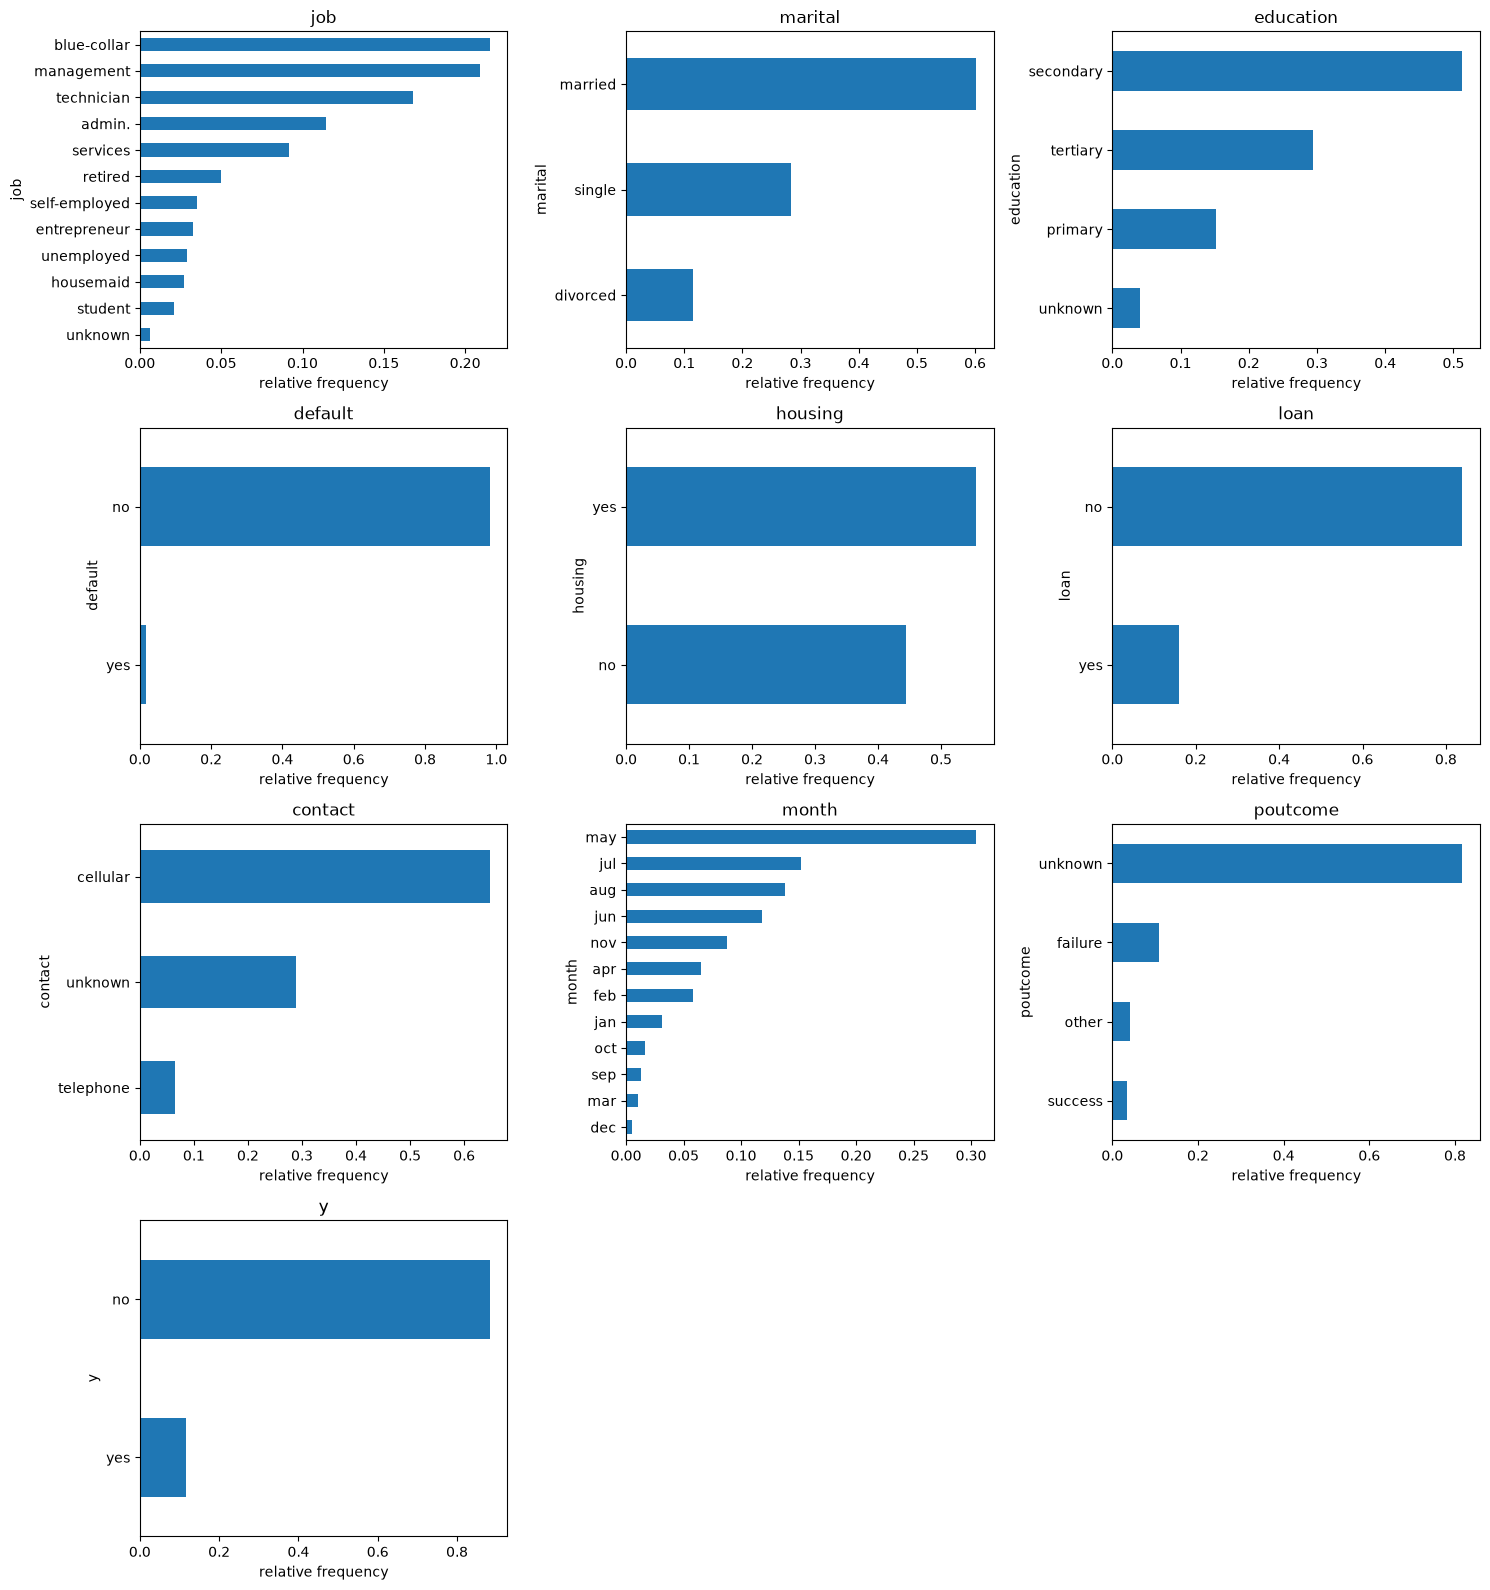

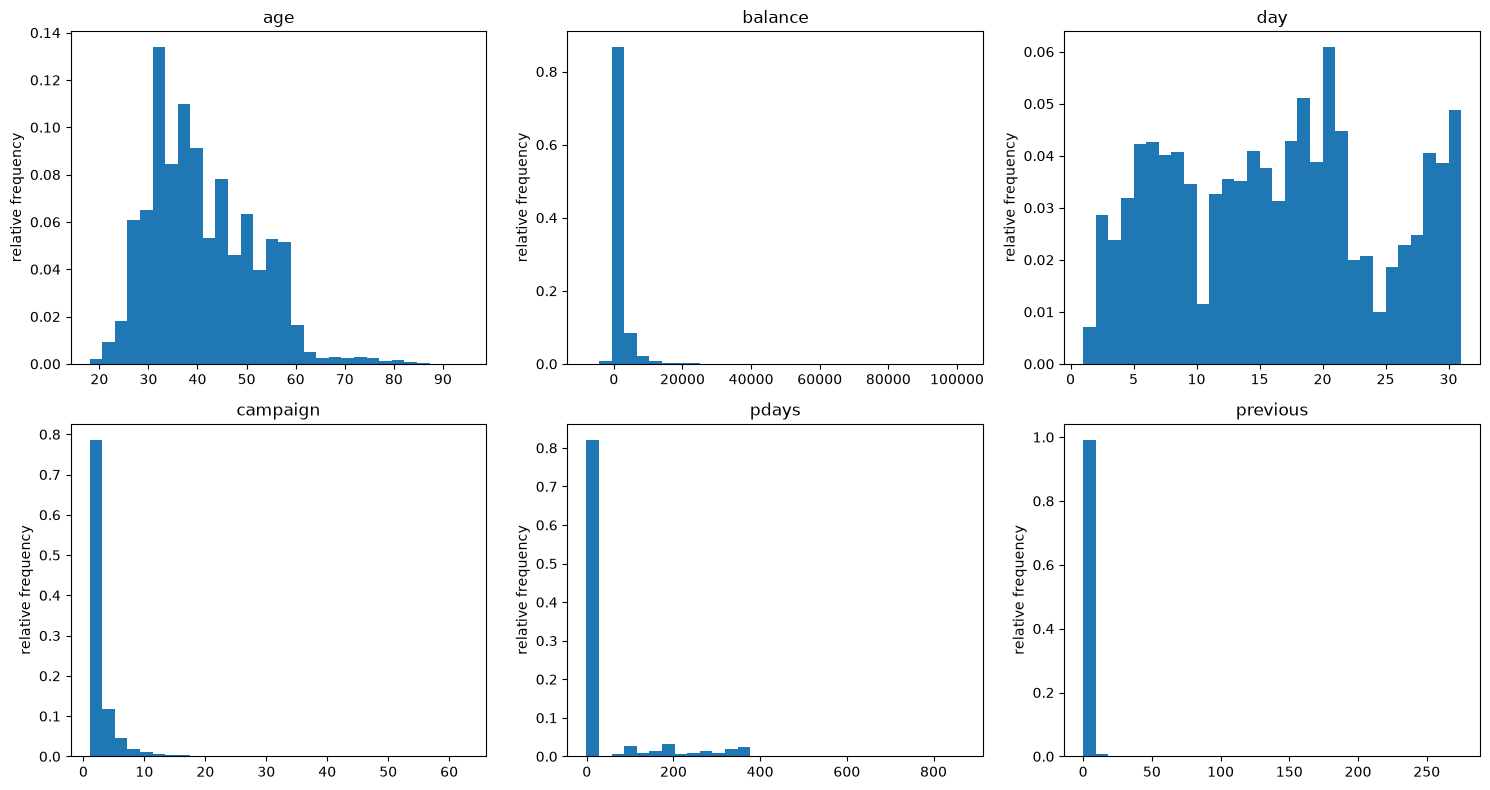

In [67]:
import numpy as np
import matplotlib.pyplot as plt

data = df.drop(columns="duration")   # original data, before imputation

cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "poutcome", "y"]
num_cols = ["age", "balance", "day", "campaign", "pdays", "previous"]

# Categorical: share of customers in each category
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, col in zip(axes.flat, cat_cols):
    data[col].value_counts(normalize=True).sort_values().plot(kind="barh", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("relative frequency")
for ax in axes.flat[len(cat_cols):]:
    ax.axis("off")                    # hide the 2 empty panels
plt.tight_layout()
plt.show()

# Numerical: histogram where each bar is a share of all customers
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    ax.hist(data[col], bins=30, weights=np.ones(len(data)) / len(data))
    ax.set_title(col)
    ax.set_ylabel("relative frequency")
plt.tight_layout()
plt.show()

## Step 8. Train/test 분할 + job → education 대체 (Standard B, Sec. 3.1)
1. **분할:** 80/20, stratified, `random_state = 42`. 대체 **전에** 나눠야 test 정보가 규칙 학습에 섞이지 않습니다.
2. **학습:** 둘 다 알려진 training 행(`known`)에서 job별 가장 흔한 education을 구합니다 → `job_to_edu`.
3. **적용:** education이 `unknown`인 행을 그 사람의 job으로 채웁니다. job도 `unknown`이면 그대로 `unknown`.
- 라벨: **Adaptation** (논문 Y. Dong 2024, Sec. 2, p. 139는 job ↔ education 추론을 하지만 기준은 밝히지 않음).
- `train_test_split`은 새 DataFrame을 만들기 때문에, 여기서 `X_train`/`X_test`를 바꿔도 원본 `df`는 바뀌지 않습니다.

In [29]:
from sklearn.model_selection import train_test_split

# 1. Split
X = df.drop(columns="y")
y = (df["y"] == "yes").astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 2. Learn: most common education for each job (training data only)
known = X_train[(X_train["job"] != "unknown") & (X_train["education"] != "unknown")]
job_to_edu = known.groupby("job")["education"].agg(lambda s: s.mode()[0])
print(job_to_edu)

# 3. Fill unknown education using the job
for data in [X_train, X_test]:
    mask = data["education"] == "unknown"
    data.loc[mask, "education"] = data.loc[mask, "job"].map(job_to_edu).fillna("unknown")

job
admin.           secondary
blue-collar      secondary
entrepreneur      tertiary
housemaid          primary
management        tertiary
retired          secondary
self-employed     tertiary
services         secondary
student          secondary
technician       secondary
unemployed       secondary
Name: education, dtype: str


**8-1. 이 매핑이 얼마나 잘 맞는지** (job별로 가장 흔한 education의 비율 = 추측 정확도)
- 결과: 0.45 (retired) ~ 0.86 (services). 모든 job이 0.45 이상이라 **전부 적용**했습니다.
- (원래는 Step 9 뒤에 실행한 셀인데, 같은 `known`을 쓰는 위 셀 바로 뒤로 옮겼습니다. 결과는 같습니다.)

In [42]:
print(known.groupby("job")["education"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).round(2))

job
admin.           0.85
blue-collar      0.58
entrepreneur     0.49
housemaid        0.52
management       0.85
retired          0.45
self-employed    0.55
services         0.86
student          0.67
technician       0.71
unemployed       0.58
Name: education, dtype: float64


**8-2. 남은 education `unknown`**
- 결과: train 103 / test 24. 남은 행은 job도 `unknown`이라 채울 수 없는 행입니다.

In [35]:
print("Education unknown -> train:", (X_train["education"] == "unknown").sum(),
      "| test:", (X_test["education"] == "unknown").sum())

Education unknown -> train: 103 | test: 24


## Step 9. job 대체 규칙 적용 (Standard Sec. 3.1)

**기준 (실무적 판단, Adaptation):** Y. Dong (2024)는 "관계가 합리적일 때만" 대체했다고 하지만 기준을 밝히지 않습니다. 그래서 "그룹에서 가장 흔한 값으로 추측하면 얼마나 맞나"를 training 데이터로 재고, 뚜렷하게 맞는 규칙만 적용했습니다 (적용한 규칙 0.45–0.86, 버린 규칙 0.28 이하). 규칙별 수치와 통계 근거는 **Step 12**에 있습니다.

"규칙을 고른 근거는 Step 12"

**9-1. 적용: 60세 이상이고 job이 `unknown`이면 → retired**
- 근거: job을 아는 60세 이상 고객의 62%가 retired (Step 12-2).
- NYU 노트북은 `age > 60`이지만, 우리는 60+ 나이 그룹에 맞춰 `age >= 60`을 씁니다 (작은 차이, 보고서에 명시).

In [38]:
for data in [X_train, X_test]:
    mask = (data["job"] == "unknown") & (data["age"] >= 60)
    data.loc[mask, "job"] = "retired"

**9-2. 적용: education이 primary / tertiary이고 job이 `unknown`이면 → blue-collar / management**
- 근거: primary → blue-collar 0.555, tertiary → management 0.589 (Step 12-4). secondary → blue-collar(0.24)는 기준에 못 미쳐 쓰지 않습니다.

In [40]:
edu_to_job = {"primary": "blue-collar", "tertiary": "management"}

for data in [X_train, X_test]:
    mask = (data["job"] == "unknown") & (data["education"].isin(edu_to_job))
    data.loc[mask, "job"] = data.loc[mask, "education"].map(edu_to_job)

**9-3. 남은 `unknown` 개수**
- 결과: job train 144 / test 34, education train 103 / test 24. 남은 값은 자체 범주 `unknown`으로 둡니다.

In [41]:
for col in ["job", "education"]:
    print(col, "-> train:", (X_train[col] == "unknown").sum(),
          "| test:", (X_test[col] == "unknown").sum())

job -> train: 144 | test: 34
education -> train: 103 | test: 24


## Step 10. `duration` 제거 (**Replication**, Y. Dong 2024 Sec. 2)
- 통화 시간은 통화가 **끝나야** 알 수 있으므로, 통화 전 예측에 쓰면 leakage입니다.
- `X_train`/`X_test`에서만 빠지고 원본 `df`에는 남아 있습니다 (그래프, 중복 확인처럼 원본을 볼 때 필요).

In [43]:
X_train = X_train.drop(columns="duration")
X_test  = X_test.drop(columns="duration")

print(X_train.shape, X_test.shape)  # should be 15 columns each

(36168, 15) (9043, 15)


**`previous = 275` 행의 위치**
- 결과: train 1 / test 0. **결정: 유지** (오류인지 확인할 수 없음). 트리 모델에는 영향이 거의 없고, KNN/LR 스케일링을 약간 늘릴 수 있어 한계로 기록합니다.

In [44]:
print("In train:", (X_train["previous"] == 275).sum(), "| In test:", (X_test["previous"] == 275).sum())

In train: 1 | In test: 0


## Step 11. 정리된 데이터 확인 (Standard Sec. 5)
- `full_view`는 train과 test를 다시 합친 **확인용**입니다. 모델은 `X_train`으로 학습하고 `X_test`로 평가합니다. `full_view`를 다시 분할하면 안 됩니다.
- 결과: 15개 특성 + `y` + `set`. 남은 `unknown`: job 178, education 127, contact 13,020, poutcome 36,959.

In [45]:
pd.set_option("display.max_columns", None)  # show every column

full_view = pd.concat([
    X_train.assign(y=y_train, set="train"),
    X_test.assign(y=y_test,  set="test"),
]).sort_index()

print("Shape:", full_view.shape)
print(full_view.dtypes)
display(full_view.head(10))
display(full_view.describe())

print("\nRemaining 'unknown' per column:")
cat_cols = full_view.select_dtypes(exclude="number").columns.drop("set")
for col in cat_cols:
    n = (full_view[col] == "unknown").sum()
    if n > 0:
        print(f"  {col}: {n}")

Shape: (45211, 17)
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
campaign     int64
pdays        int64
previous     int64
poutcome       str
y            int64
set            str
dtype: object


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y,set
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0,train
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0,train
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0,train
3,47,blue-collar,married,secondary,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,0,train
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,0,train
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,1,-1,0,unknown,0,train
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,1,-1,0,unknown,0,train
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,1,-1,0,unknown,0,train
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,1,-1,0,unknown,0,train
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,1,-1,0,unknown,0,test


,age,balance,day,campaign,pdays,previous,y
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,2.763841,40.197828,0.580323,0.116985
std,10.618762,3044.765829,8.322476,3.098021,100.128746,2.303441,0.321406
min,18.000000,-8019.000000,1.000000,1.000000,-1.000000,0.000000,0.000000
25%,33.000000,72.000000,8.000000,1.000000,-1.000000,0.000000,0.000000
50%,39.000000,448.000000,16.000000,2.000000,-1.000000,0.000000,0.000000
75%,48.000000,1428.000000,21.000000,3.000000,-1.000000,0.000000,0.000000
max,95.000000,102127.000000,31.000000,63.000000,871.000000,275.000000,1.000000



Remaining 'unknown' per column:
  job: 178
  education: 127
  contact: 13020
  poutcome: 36959


**11-1. `poutcome`별 구독률: `poutcome`을 유지하는 이유 (Standard Sec. 3.3)**
- 결과: success 64.7%, other 16.7%, failure 12.6%, unknown 9.2% (전체 11.7%). 이전 캠페인 성공 고객은 전체의 약 5.5배입니다.

In [46]:
print(full_view.groupby("poutcome")["y"].agg(["mean", "size"]).round(3))

           mean   size
poutcome              
failure   0.126   4901
other     0.167   1840
success   0.647   1511
unknown   0.092  36959


**11-2. job × education 교차표**
- 결과: education `unknown` 127 = job `unknown` 112 + retired 15. 이 15행은 나이 규칙으로 retired가 됐는데, education 대체가 그보다 먼저 끝나서 education은 `unknown`으로 남았습니다.
- job `unknown` 행에 primary/tertiary가 남아 있지 않습니다 → 9-5가 제대로 적용됐습니다.

In [50]:
result = pd.crosstab(full_view["job"], full_view["education"])
print(result)

education      primary  secondary  tertiary  unknown
job                                                 
admin.             209       4390       572        0
blue-collar       3807       5825       149        0
entrepreneur       183        542       762        0
housemaid          672        395       173        0
management         294       1121      8076        0
retired            797       1108       372       15
self-employed      130        577       872        0
services           345       3607       202        0
student             44        671       223        0
technician         158       5471      1968        0
unemployed         257        757       289        0
unknown              0         66         0      112


**11-3. 원본 `df`가 바뀌지 않았는지 확인**
- 3번 행(47세, blue-collar)의 education이 여기서는 `unknown`이고, 위 `full_view`에서는 `secondary`입니다.
- 즉 대체는 `X_train`/`X_test`에만 적용됐고 원본은 그대로입니다.

In [52]:
df_clean.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## Step 12. 대체 규칙의 통계적 근거 (**Extension**, Standard Sec. 3.1)
논문에는 없는 추가 검증입니다. 모두 **원본 training 행** (`df.loc[X_train.index]`)으로 계산합니다.
- Cramér's V: 두 범주형 변수의 관계 강도 (0~1). 3열 표에서 0.35 이상, 2×2 표에서 0.5 이상이면 "강함" (Cohen 1988 조정).

**12-1. job → education**
- 결과: χ² = 21,491, df = 20, p < 0.001, V = 0.56 (강함).
- 정확도: job 기반 0.706 vs 항상 "secondary"로 추측 0.535 → 오류 약 37% 감소.
- 실제로 채운 행 1,379개, 예상 정확도 0.679 → 약 440개는 틀릴 가능성 (training의 약 1.2%).
- 한계: primary는 채운 행의 2.8%에만 배정됐지만, 실제로는 17.9%가 primary일 것으로 예상됩니다.
- 셀 안의 `assert`는 `df`가 대체 전 원본인지 확인합니다 (통과).

In [62]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

orig_train = df.loc[X_train.index]   # original values for the training rows (df = data before imputation)
assert (orig_train["education"] == "unknown").sum() > (X_train["education"] == "unknown").sum(), "df is already imputed"

known = orig_train[(orig_train["job"] != "unknown") & (orig_train["education"] != "unknown")]
table = pd.crosstab(known["job"], known["education"])
n = table.values.sum()

# 1. Is there a relationship, and how strong?
chi2, p, dof, _ = chi2_contingency(table)
v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print(f"Chi-square = {chi2:.0f}, df = {dof}, {'p < 0.001' if p < 0.001 else f'p = {p:.3f}'}, Cramér's V = {v:.2f}")

# 2. How often is the guess right? Job-based guess vs always guessing the most common level
print(f"Accuracy: job-based = {table.max(axis=1).sum() / n:.3f}, global mode = {table.sum().max() / n:.3f}")

# 3. The rows you actually filled: expected accuracy and the 'primary' bias
filled = orig_train.loc[(orig_train["education"] == "unknown") & (orig_train["job"] != "unknown"), "job"].value_counts()
acc_by_job = table.max(axis=1) / table.sum(axis=1)
primary_by_job = table["primary"] / table.sum(axis=1)
guess = table.idxmax(axis=1)                      # the job -> education mapping you applied
print(f"Filled rows: {filled.sum()}, expected accuracy = {(acc_by_job[filled.index] * filled).sum() / filled.sum():.3f}")
print(f"'primary' among filled rows: assigned {filled[guess[filled.index] == 'primary'].sum() / filled.sum():.1%}, "
      f"expected {(primary_by_job[filled.index] * filled).sum() / filled.sum():.1%}")

Chi-square = 21491, df = 20, p < 0.001, Cramér's V = 0.56
Accuracy: job-based = 0.706, global mode = 0.535
Filled rows: 1379, expected accuracy = 0.679
'primary' among filled rows: assigned 2.8%, expected 17.9%


**12-2. 60세 이상 → retired**
- 결과: 나이 그룹 × job V = 0.43, 60+ × retired V = 0.53 (둘 다 강함).
- 60+ 정확도: retired 0.620 vs 항상 blue-collar 0.057. 은퇴자 비율 60+ 62.0% vs 60 미만 2.7%.
- 채운 행 23개 (training). 60+의 38%는 은퇴자가 아니므로 약 9개는 틀릴 가능성.

In [63]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

orig_train = df.loc[X_train.index]   # original values for the training rows (df = data before imputation)
known = orig_train[orig_train["job"] != "unknown"]
is_60plus = known["age"] >= 60
is_retired = known["job"] == "retired"

def cramers_v(table):
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    return f"Chi-square = {chi2:.0f}, df = {dof}, {p_text}, Cramér's V = {v:.2f}"

# 1. Is age related to job in general? (3 age groups x 11 jobs)
age_group = pd.cut(known["age"], bins=[17, 29, 59, 100], labels=["18-29", "30-59", "60+"])
print("Age group x job:  ", cramers_v(pd.crosstab(age_group, known["job"])))

# 2. Is the specific rule supported? (60+ yes/no x retired yes/no)
print("60+ x retired:    ", cramers_v(pd.crosstab(is_60plus, is_retired)))

# 3. How often is the guess right for 60+ customers? Rule vs always guessing the most common job
global_mode = known["job"].mode()[0]
print(f"Accuracy for 60+: rule ('retired') = {is_retired[is_60plus].mean():.3f}, "
      f"global mode ('{global_mode}') = {(known.loc[is_60plus, 'job'] == global_mode).mean():.3f}  (n = {is_60plus.sum()})")

# 4. How much more common is 'retired' at 60+?
print(f"Retired share: 60+ = {is_retired[is_60plus].mean():.1%}, under 60 = {is_retired[~is_60plus].mean():.1%}")

# 5. Rows the rule actually changed (training)
print("Rows filled by the rule (training):", ((orig_train["job"] == "unknown") & (orig_train["age"] >= 60)).sum())

Age group x job:   Chi-square = 13505, df = 20, p < 0.001, Cramér's V = 0.43
60+ x retired:     Chi-square = 10049, df = 1, p < 0.001, Cramér's V = 0.53
Accuracy for 60+: rule ('retired') = 0.620, global mode ('blue-collar') = 0.057  (n = 1424)
Retired share: 60+ = 62.0%, under 60 = 2.7%
Rows filled by the rule (training): 23


**12-3. 버린 규칙: loan / housing → job**
- 결과: loan V = 0.10, 정확도 0.219 vs 전체 최빈값 0.218 (개선 없음). housing V = 0.28, 정확도 0.264 (74%는 틀림).

In [64]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

orig_train = df.loc[X_train.index]
known = orig_train[orig_train["job"] != "unknown"]

def cramers_v(table):
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    return f"Chi-square = {chi2:.0f}, df = {dof}, {p_text}, Cramér's V = {v:.2f}"

global_mode = known["job"].mode()[0]
global_acc = (known["job"] == global_mode).mean()

for col in ["loan", "housing"]:
    table = pd.crosstab(known[col], known["job"])
    rule_acc = table.max(axis=1).sum() / table.values.sum()   # guess the most common job per group
    print(f"{col} x job: {cramers_v(table)}")
    print(f"   Accuracy: {col}-based = {rule_acc:.3f}, global mode ('{global_mode}') = {global_acc:.3f}\n")

loan x job: Chi-square = 389, df = 10, p < 0.001, Cramér's V = 0.10
   Accuracy: loan-based = 0.219, global mode ('blue-collar') = 0.218

housing x job: Chi-square = 2730, df = 10, p < 0.001, Cramér's V = 0.28
   Accuracy: housing-based = 0.264, global mode ('blue-collar') = 0.218



**12-4. education → job**
- 결과: V = 0.56. primary → blue-collar 0.555 (n = 5,487), tertiary → management 0.589 (n = 10,564, 항상 blue-collar로 추측하면 0.011).
- 이 셀은 바로 위 셀의 `known`과 `cramers_v`를 이어서 씁니다. 순서를 바꾸면 안 됩니다.

In [65]:
edu_known = known[known["education"] != "unknown"]          # known = training rows with known job (from the last cell)
table = pd.crosstab(edu_known["education"], edu_known["job"])
print("Education x job:", cramers_v(table))
for level in ["primary", "tertiary"]:
    grp = edu_known.loc[edu_known["education"] == level, "job"]
    print(f"{level}: rule ('{grp.mode()[0]}') = {(grp == grp.mode()[0]).mean():.3f}, "
          f"global mode ('blue-collar') = {(grp == 'blue-collar').mean():.3f}  (n = {len(grp)})")

Education x job: Chi-square = 21491, df = 20, p < 0.001, Cramér's V = 0.56
primary: rule ('blue-collar') = 0.555, global mode ('blue-collar') = 0.555  (n = 5487)
tertiary: rule ('management') = 0.589, global mode ('blue-collar') = 0.011  (n = 10564)


## Step 13. One-hot 인코딩 (**Adaptation**, Standard B3 #1)
- Y. Dong (2024)는 인코딩 방법을 밝히지 않습니다. NYU 노트북처럼 각 변수에서 **첫 범주 하나를 빼고** (n−1개 열) 만듭니다. Logistic Regression에서 열끼리 완전히 겹치는 문제를 막기 위해서입니다.
- 범주 목록은 `X_train`에서만 학습하고, test에는 적용만 합니다.
- 결과: (36,168, 41) / (9,043, 41). 기준(빠진) 범주: job admin., marital divorced, education primary, default/housing/loan no, contact cellular, month apr, poutcome failure.

In [68]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[cat_cols])                      # learn categories from training data only

def encode(data):
    encoded = pd.DataFrame(encoder.transform(data[cat_cols]),
                           columns=encoder.get_feature_names_out(cat_cols),
                           index=data.index).astype(int)
    return pd.concat([data[num_cols], encoded], axis=1)

X_train_enc = encode(X_train)
X_test_enc = encode(X_test)

print("Shapes:", X_train_enc.shape, X_test_enc.shape)
print("Reference (dropped) category:", {c: str(cats[0]) for c, cats in zip(cat_cols, encoder.categories_)})

Shapes: (36168, 41) (9043, 41)
Reference (dropped) category: {'job': 'admin.', 'marital': 'divorced', 'education': 'primary', 'default': 'no', 'housing': 'no', 'loan': 'no', 'contact': 'cellular', 'month': 'apr', 'poutcome': 'failure'}


## Step 14. 교차검증 + 튜닝: training set만 사용 (Standard B3, B4)

| 항목 | 선택 | 라벨 |
|---|---|---|
| 모델 | LR, KNN, Decision Tree, Random Forest (Y. Dong Sec. 3) | Replication |
| 스케일링 | StandardScaler를 Pipeline 안에서 (LR, KNN만). fold마다 따로 fit | Adaptation |
| 검증 | `StratifiedKFold(5, shuffle=True)`. 데이터가 날짜순이라 섞음 | Replication + adaptation |
| 튜닝 기준 | ROC-AUC (Y. Dong Sec. 3.2는 KNN의 k를 AUC로 선택), KNN에 k = 60 포함 | Replication (KNN) / adaptation |
| Class weight | `"balanced"` + 가중치 없음 둘 다 (KNN은 옵션 없음) | Extension |

- 결과: Random Forest (balanced) 0.7943이 가장 높고, LR 약 0.764, KNN 0.760, DT balanced 0.768 / none 0.748.
- **Test set은 아직 쓰지 않았습니다.**
- 남은 확인 (B4): 일부 최적값이 그리드 끝에 걸려 있습니다 (KNN k = 100, DT max_depth 10, LR C = 0.01). 최종 평가 전에 그리드를 한 단계 넓혀 확인해야 합니다.

In [69]:
# Step 2: cross-validation and tuning on the training set. This runs the four models with 5-fold shuffled CV, picks the best settings by ROC-AUC, and does each weighted model twice (balanced and unweighted):
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # shuffled: the data is ordered by date

def make_model(name, weight):
    """Returns (model, small settings grid). Scaling only for LR and KNN."""
    if name == "Logistic Regression":
        model = Pipeline([("scale", StandardScaler()),
                          ("model", LogisticRegression(class_weight=weight, max_iter=1000))])
        grid = {"model__C": [0.01, 0.1, 1, 10]}
    elif name == "KNN":                                   # no class_weight option in scikit-learn
        model = Pipeline([("scale", StandardScaler()),
                          ("model", KNeighborsClassifier())])
        grid = {"model__n_neighbors": [15, 30, 60, 100]}  # includes Y. Dong's k = 60
    elif name == "Decision Tree":
        model = DecisionTreeClassifier(class_weight=weight, random_state=42)
        grid = {"max_depth": [3, 5, 7, 10], "min_samples_leaf": [1, 20, 100]}
    else:  # Random Forest
        model = RandomForestClassifier(n_estimators=200, class_weight=weight, random_state=42, n_jobs=-1)
        grid = {"max_depth": [5, 10, None], "min_samples_leaf": [1, 5, 20]}
    return model, grid

runs = [("Logistic Regression", "balanced"), ("Logistic Regression", None),
        ("KNN", None),
        ("Decision Tree", "balanced"), ("Decision Tree", None),
        ("Random Forest", "balanced"), ("Random Forest", None)]

searches, rows = {}, []
for name, weight in runs:
    model, grid = make_model(name, weight)
    search = GridSearchCV(model, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train_enc, y_train)
    label = "balanced" if weight else "none"
    searches[(name, label)] = search
    i = search.best_index_
    rows.append({"Model": name, "Class weight": label,
                 "CV AUC (mean)": round(search.cv_results_["mean_test_score"][i], 4),
                 "CV AUC (std)": round(search.cv_results_["std_test_score"][i], 4),
                 "Best settings": search.best_params_})
    print(f"{name} ({label}) done")

cv_table = pd.DataFrame(rows)
print(cv_table.to_string(index=False))


Logistic Regression (balanced) done
Logistic Regression (none) done
KNN (none) done
Decision Tree (balanced) done
Decision Tree (none) done
Random Forest (balanced) done
Random Forest (none) done
              Model Class weight  CV AUC (mean)  CV AUC (std)                              Best settings
Logistic Regression     balanced         0.7639        0.0032                         {'model__C': 0.01}
Logistic Regression         none         0.7633        0.0028                         {'model__C': 0.01}
                KNN         none         0.7603        0.0044                {'model__n_neighbors': 100}
      Decision Tree     balanced         0.7679        0.0062  {'max_depth': 10, 'min_samples_leaf': 20}
      Decision Tree         none         0.7484        0.0045 {'max_depth': 10, 'min_samples_leaf': 100}
      Random Forest     balanced         0.7943        0.0031 {'max_depth': None, 'min_samples_leaf': 5}
      Random Forest         none         0.7922        0.0044 {'max_d

## 다음 단계 (아직 하지 않음)
1. 그리드 끝에 걸린 설정을 한 단계 넓혀 다시 CV (B4).
2. 최적 설정으로 training 전체에 다시 학습 → test set으로 **한 번만** 평가.
3. 지표 (Y. Dong Sec. 4): accuracy (기준선 0.883과 함께), AUC, KS, cumulative lift.